# Exploration : la consommation d'électricité en France (2012-2023)

Objectif : comprendre la série **avant** de choisir les modèles. Quatre questions :
1. Quelles saisonnalités ? 2. Les jours fériés comptent-ils ? 3. La série est-elle stationnaire ? 4. Que s'est-il passé en 2022 ?

Données : RTE éCO2mix, consommation nationale au pas de 30 minutes, agrégée en énergie journalière (GWh).

In [1]:
import sys; sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
from prevision.data import load_halfhourly, load_daily, calendar_features
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})
y = load_daily()
print(f"{len(y)} jours, de {y.index[0]:%d/%m/%Y} à {y.index[-1]:%d/%m/%Y} ; moyenne {y.mean():.0f} GWh/jour")

4383 jours, de 01/01/2012 à 31/12/2023 ; moyenne 1283 GWh/jour


## 1. Trois saisonnalités imbriquées

**Dans la journée** (pas de 30 minutes) : pointe du matin et du soir.

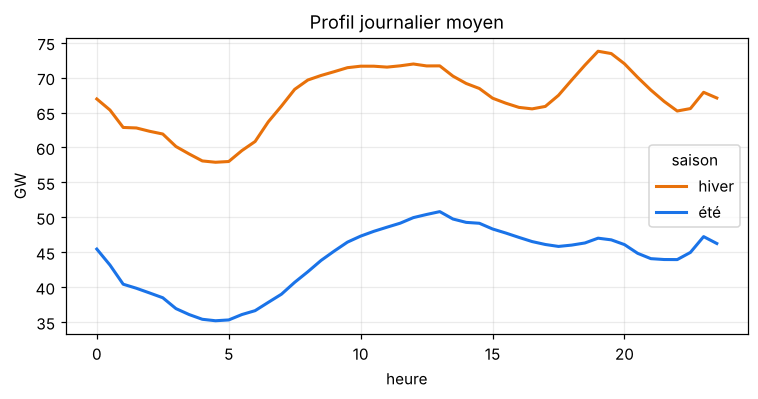

In [2]:
h = load_halfhourly()
h['heure'] = h['horodatage'].dt.hour + h['horodatage'].dt.minute / 60
h['saison'] = np.where(h['horodatage'].dt.month.isin([12, 1, 2]), 'hiver', np.where(h['horodatage'].dt.month.isin([6, 7, 8]), 'été', None))
prof = h.dropna(subset=['saison']).groupby(['saison', 'heure'])['consommation_mw'].mean().unstack(0) / 1000
ax = prof.plot(figsize=(8, 3.5), color=['#e8710a', '#1a73e8'], lw=2); ax.set_ylabel('GW'); ax.set_title('Profil journalier moyen');

**Dans la semaine et dans l'année** : la décomposition STL sépare tendance, saison annuelle et reste.

Facteur saisonnier : de 0.69 (été) à 1.63 (hiver) → un jour d'hiver consomme 2.3 fois plus qu'un jour d'été


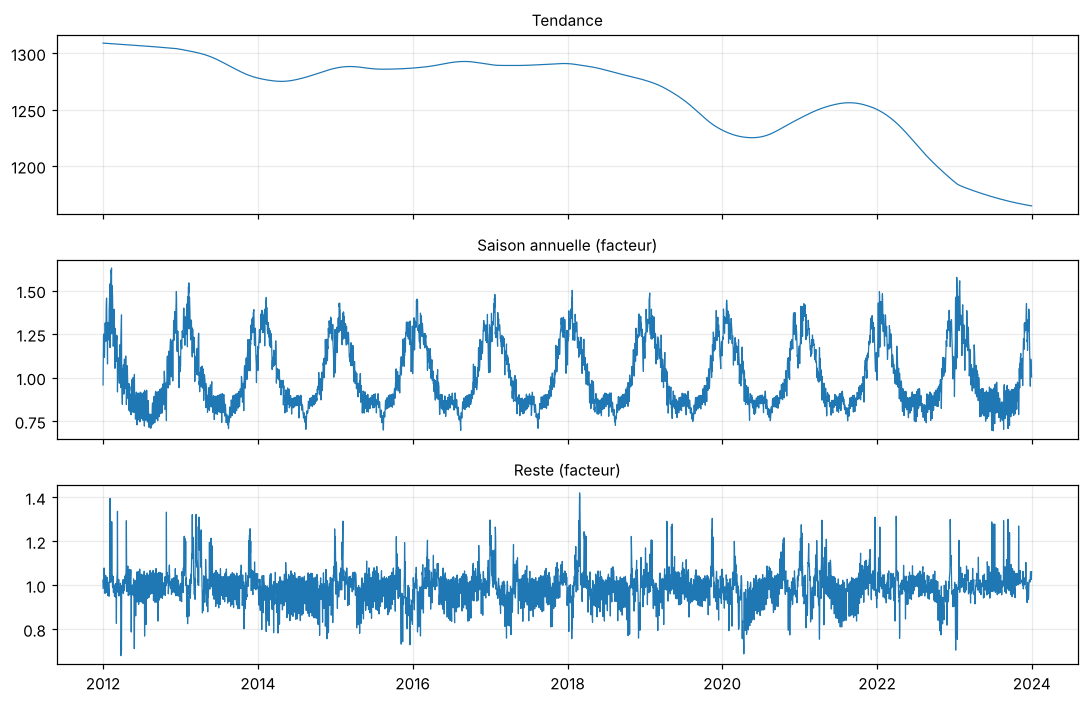

In [3]:
stl = STL(np.log(y), period=365, robust=True).fit()
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax, (name, s) in zip(axes, [('Tendance', np.exp(stl.trend)), ('Saison annuelle (facteur)', np.exp(stl.seasonal)), ('Reste (facteur)', np.exp(stl.resid))]):
    ax.plot(s, lw=.8); ax.set_title(name, fontsize=10)
plt.tight_layout()
ann = np.exp(stl.seasonal)
print(f"Facteur saisonnier : de {ann.min():.2f} (été) à {ann.max():.2f} (hiver) → un jour d'hiver consomme {ann.max()/ann.min():.1f} fois plus qu'un jour d'été")

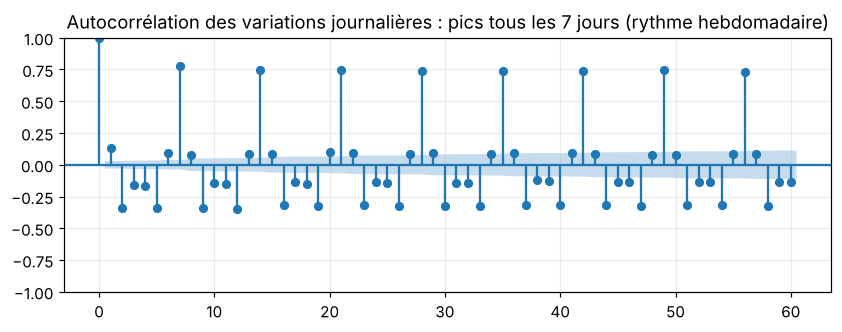

In [4]:
fig, ax = plt.subplots(figsize=(9, 3)); plot_acf(y.diff(1).dropna(), lags=60, ax=ax)
ax.set_title("Autocorrélation des variations journalières : pics tous les 7 jours (rythme hebdomadaire)");

## 2. Les jours fériés : un « dimanche » en pleine semaine

In [5]:
f = calendar_features(y.index)
sem = y[(f['jour_semaine'] < 5)]
ratio = pd.Series({
    'jour ouvré normal': 1.0,
    'jour férié (lun-ven)': sem[f.loc[sem.index, 'ferie'] == 1].mean() / sem[(f.loc[sem.index, 'ferie'] == 0) & (f.loc[sem.index, 'pont'] == 0)].mean(),
    'pont': sem[f.loc[sem.index, 'pont'] == 1].mean() / sem[(f.loc[sem.index, 'ferie'] == 0) & (f.loc[sem.index, 'pont'] == 0)].mean(),
    'dimanche': y[f['jour_semaine'] == 6].mean() / sem.mean(),
})
print((ratio * 100).round(1).astype(str) + ' %')

jour ouvré normal       100.0 %
jour férié (lun-ven)     82.3 %
pont                     86.5 %
dimanche                 86.5 %
dtype: str


Un jour férié en semaine fait chuter la consommation de **18 %**, autant voire plus qu'un dimanche (−13 %) ;
un **pont** la fait baisser de **13 %**, comme un dimanche.
**Conséquence pour les modèles** : sans variable « jour férié », un modèle se trompe lourdement ces jours-là. SARIMAX, Prophet et LightGBM la reçoivent ; les modèles naïfs et ETS non.

## 3. Stationnarité

In [6]:
for name, s in [('série brute', y), ('différence à 7 jours', y.diff(7).dropna())]:
    stat, p, *_ = adfuller(s, maxlag=30)
    print(f"Test ADF – {name:22s} p-value = {p:.4f}")

Test ADF – série brute            p-value = 0.0000
Test ADF – différence à 7 jours   p-value = 0.0000


Le test ADF rejette la racine unitaire dans les deux cas, mais la série brute a une forte saisonnalité :
on travaille donc sur le **logarithme** (les variations saisonnières sont proportionnelles au niveau)
avec une **différence saisonnière à 7 jours** dans SARIMA, et des **termes de Fourier** pour la saison annuelle
(une saison de 365 jours est trop longue pour un SARIMA classique).

## 4. 2022 : la crise énergétique et la sobriété

Hiver 2022-2023 (nov-fév) : -9.5 % par rapport à 2014-2019


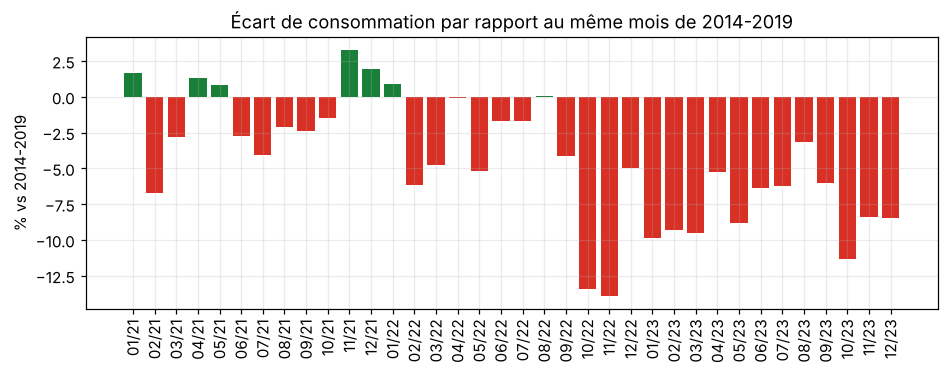

In [7]:
# on compare chaque mois à la moyenne du même mois sur 2014-2019, pour neutraliser la saison
ref = y['2014':'2019'].groupby(y['2014':'2019'].index.month).mean()
recent = y['2021':]
m = recent.groupby([recent.index.year, recent.index.month]).mean()
ecart = pd.Series((m.to_numpy() / ref.reindex([mo for _, mo in m.index]).to_numpy() - 1) * 100,
                  index=[f"{mo:02d}/{an % 100}" for an, mo in m.index])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(ecart.index, ecart, color=np.where(ecart < 0, '#d93025', '#188038'))
ax.tick_params(axis='x', rotation=90); ax.set_ylabel('% vs 2014-2019')
ax.set_title('Écart de consommation par rapport au même mois de 2014-2019')
hiver = ecart[['11/22', '12/22', '01/23', '02/23']].mean()
print(f"Hiver 2022-2023 (nov-fév) : {hiver:.1f} % par rapport à 2014-2019")

À partir de l'automne 2022, la consommation décroche nettement (prix de l'énergie, plan de sobriété, météo douce).
C'est une **rupture de niveau** : le piège pour un modèle entraîné sur le passé. C'est pourquoi la période de test
(2022-2023) est exigeante, et pourquoi les modèles retenus s'appuient sur le **niveau récent** plutôt que sur des moyennes historiques.

## Ce que l'on retient pour la modélisation
- prévoir le **logarithme**, avec saisons **hebdomadaire** (7 jours) et **annuelle** (Fourier) ;
- intégrer **jours fériés, ponts et fêtes de fin d'année** ;
- s'ancrer sur le **niveau récent** pour encaisser les ruptures (Covid, sobriété) ;
- limite assumée : **sans la température**, aucun modèle ne peut anticiper une vague de froid.